<a href="https://colab.research.google.com/github/chundawat-h/Receipt-Invoice-Information-Extraction/blob/model%2Fbert-text-only/bert-text-only/notebooks/03_bert_text_only.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Method 2 — BERT Token Classification (text only)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/chundawat-h/Receipt-Invoice-Information-Extraction/blob/main/notebooks/03_bert_text_only.ipynb)

**Issue #5** (Hiranya). Fine-tune `bert-base-uncased` to label every OCR word as `B-/I-COMPANY`, `DATE`, `ADDRESS`, `TOTAL` or `O`. The model sees **only the text**, no positions. LayoutLM (#6) gets the same words **plus** their boxes, so the difference between the two answers our research question.

**Run in Colab:** Runtime → Change runtime type → **T4 GPU**, then Runtime → Run all (training takes about 10 minutes).

Outputs saved to `results/`:

| File | Contents |
|---|---|
| `bert_preds.json` | field predictions per receipt key, the input to `evaluate()` and #7 |
| `bert_word_preds.json` | predicted label for every word, for error analysis (#7) |
| `bert_scores.csv`, `bert_scores_official.csv` | field-level P/R/F1 vs tagged-word gold / official answers |
| `bert_seqeval.txt` | word-level seqeval classification report |
| `bert_hparams.json` | exact hyperparameters, GPU and training time. **LayoutLM must use the same** |
| `bert_training_log.csv`, `bert_training_loss.png`, `bert_f1.png` | training curve and F1 chart |

No model weights are saved (no checkpoints, nothing written to the repo).

In [1]:
!pip install -q transformers "datasets<3" seqeval

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gcsfs 2025.12.0 requires fsspec==2025.12.0, but you have fsspec 2024.6.1 which is incompatible.


In [2]:
# Make `src/` importable. In a fresh Colab runtime the repo isn't there yet, so clone it.
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/chundawat-h/Receipt-Invoice-Information-Extraction.git"
if Path("../src").is_dir():            # running from notebooks/ inside the repo
    ROOT = Path("..")
elif Path("src").is_dir():
    ROOT = Path(".")
else:                                  # Colab (clone once; re-running the cell reuses it)
    ROOT = Path("Receipt-Invoice-Information-Extraction")
    if not ROOT.is_dir():
        subprocess.run(["git", "clone", "-q", REPO_URL], check=True)
sys.path.insert(0, str(ROOT.resolve()))
RESULTS = ROOT / "results"
RESULTS.mkdir(exist_ok=True)

### Notes from data exploration (#4)
- Only 4 train / 1 test receipts exceed 512 sub-tokens, and the words cut off are never field words, so `truncation=True, max_length=512` is fine. Give cut-off words the label `"O"` before calling `bio_to_fields`, otherwise it raises a length mismatch.
- Evaluate on the 347 test receipts and save `results/bert_preds.json` keyed by `row["key"]`.
- Don't use the test split for checkpoint selection (no `load_best_model_at_end` on test). Train the fixed 10 epochs, then evaluate once.

In [3]:
from src.data import LABEL2ID, LABELS, ID2LABEL, load_sroie

# Word-tagged SROIE (darentang/sroie, Parquet copy): train 626 / test 347.
# Columns: id, words, bboxes (already 0-1000), ner_tags, image_path, key.
# Save predictions keyed by row["key"] (e.g. "X51005230621"), not by row index.
ds = load_sroie()
ds

Generating train split: 0 examples [00:00, ? examples/s]

Generating test split: 0 examples [00:00, ? examples/s]

Map:   0%|          | 0/626 [00:00<?, ? examples/s]

Map:   0%|          | 0/347 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['id', 'words', 'bboxes', 'ner_tags', 'image_path', 'key'],
        num_rows: 626
    })
    test: Dataset({
        features: ['id', 'words', 'bboxes', 'ner_tags', 'image_path', 'key'],
        num_rows: 347
    })
})

## 1. Hyperparameters

These are fixed in advance (issue #5). There is no validation split and the test set is used **once**, after training. There's no early stopping and no checkpoint selection. LayoutLM (#6) uses exactly the same values.

In [4]:
import json
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import transformers
from transformers import (
    AutoModelForTokenClassification,
    AutoTokenizer,
    DataCollatorForTokenClassification,
    Trainer,
    TrainingArguments,
    set_seed,
)

HP = {
    "model": "bert-base-uncased",
    "max_length": 512,
    "learning_rate": 5e-5,
    "epochs": 10,
    "batch_size": 8,
    "weight_decay": 0.0,
    "warmup_steps": 0,
    "lr_scheduler": "linear",
    "optimizer": "AdamW (Trainer default)",
    "fp16": True,
    "seed": 42,
}

GPU = torch.cuda.get_device_name(0) if torch.cuda.is_available() else None
if GPU is None:
    print("WARNING: no GPU found. In Colab: Runtime -> Change runtime type -> T4 GPU. "
          "Training on CPU takes hours; fp16 is switched off.")
    HP["fp16"] = False
print("GPU:", GPU, "| transformers", transformers.__version__, "| torch", torch.__version__)
set_seed(HP["seed"])
pd.DataFrame(HP.items(), columns=["hyperparameter", "value"]).set_index("hyperparameter")

GPU: Tesla T4 | transformers 5.22.1 | torch 2.14.1+cu130


,value
hyperparameter,
model,bert-base-uncased
max_length,512
learning_rate,0.00005
epochs,10
batch_size,8
weight_decay,0.0
warmup_steps,0
lr_scheduler,linear
optimizer,AdamW (Trainer default)


## 2. Tokenise and align labels

BERT splits words into WordPiece sub-tokens (`9.000` → `9`, `.`, `000`). Only the **first sub-token of each word** carries the word's label. The other sub-tokens and the special tokens `[CLS]`/`[SEP]` get `-100`, so the loss ignores them. Receipts longer than 512 sub-tokens are truncated. Data exploration (#4) showed this affects 4 train / 1 test receipts and never cuts a field word.

In [5]:
tokenizer = AutoTokenizer.from_pretrained(HP["model"])
MAX_LEN = HP["max_length"]

def align_labels(word_ids, word_tags):
    # First sub-token of each word -> the word's tag; everything else -> -100 (ignored by the loss)
    labels, previous = [], None
    for w in word_ids:
        labels.append(-100 if w is None or w == previous else word_tags[w])
        previous = w
    return labels

def encode(batch):
    enc = tokenizer(batch["words"], is_split_into_words=True, truncation=True, max_length=MAX_LEN)
    enc["labels"] = [align_labels(enc.word_ids(i), tags) for i, tags in enumerate(batch["ner_tags"])]
    return enc

encoded = ds.map(encode, batched=True, remove_columns=ds["train"].column_names)
encoded

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Map:   0%|          | 0/626 [00:00<?, ? examples/s]

Map:   0%|          | 0/347 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['input_ids', 'token_type_ids', 'attention_mask', 'labels'],
        num_rows: 626
    })
    test: Dataset({
        features: ['input_ids', 'token_type_ids', 'attention_mask', 'labels'],
        num_rows: 347
    })
})

In [6]:
# What the model sees for the start of one receipt
row, enc = ds["train"][0], encoded["train"][0]
word_ids = tokenizer(row["words"], is_split_into_words=True, truncation=True, max_length=MAX_LEN).word_ids()
pd.DataFrame({
    "sub-token": tokenizer.convert_ids_to_tokens(enc["input_ids"]),
    "word": [row["words"][w] if w is not None else "" for w in word_ids],
    "label": [ID2LABEL[l] if l != -100 else "-100 (ignored)" for l in enc["labels"]],
}).head(25)

,sub-token,word,label
0,[CLS],,-100 (ignored)
1,tan,tan,O
2,woo,woon,O
3,##n,woon,-100 (ignored)
4,yan,yann,O
5,##n,yann,-100 (ignored)
6,book,BOOK,B-COMPANY
7,ta,TA,I-COMPANY
8,_,_K,I-COMPANY
9,k,_K,-100 (ignored)


## 3. Train

In [7]:
model = AutoModelForTokenClassification.from_pretrained(
    HP["model"], num_labels=len(LABELS), id2label=ID2LABEL, label2id=LABEL2ID
)

args = TrainingArguments(
    output_dir="outputs/bert",           # git-ignored; nothing is saved there (save_strategy="no")
    learning_rate=HP["learning_rate"],
    num_train_epochs=HP["epochs"],
    per_device_train_batch_size=HP["batch_size"],
    per_device_eval_batch_size=16,
    weight_decay=HP["weight_decay"],
    warmup_steps=HP["warmup_steps"],
    lr_scheduler_type=HP["lr_scheduler"],
    fp16=HP["fp16"],
    seed=HP["seed"],
    eval_strategy="no",                  # no validation split; test is used once, after training
    save_strategy="no",                  # no checkpoints / weights
    logging_steps=10,
    report_to="none",
)

trainer = Trainer(
    model=model,
    args=args,
    train_dataset=encoded["train"],
    data_collator=DataCollatorForTokenClassification(tokenizer),
    processing_class=tokenizer,
)

start = time.time()
train_result = trainer.train()
TRAIN_MINUTES = (time.time() - start) / 60
print(f"Training took {TRAIN_MINUTES:.1f} min on {GPU or 'CPU'}")
train_result.metrics

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertForTokenClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
bert.pooler.dense.weight                   | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
bert.pooler.dense.bias                     | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly

Step,Training Loss
10,1.174876
20,0.278750
30,0.166563
40,0.103611
50,0.093400
60,0.087533
70,0.085167
80,0.072848
90,0.059098
100,0.055187


Training took 2.3 min on Tesla T4


{'train_runtime': 138.0346,
 'train_samples_per_second': 45.351,
 'train_steps_per_second': 5.723,
 'total_flos': 1164797880407928.0,
 'train_loss': 0.03983705192332781,
 'epoch': 10.0}

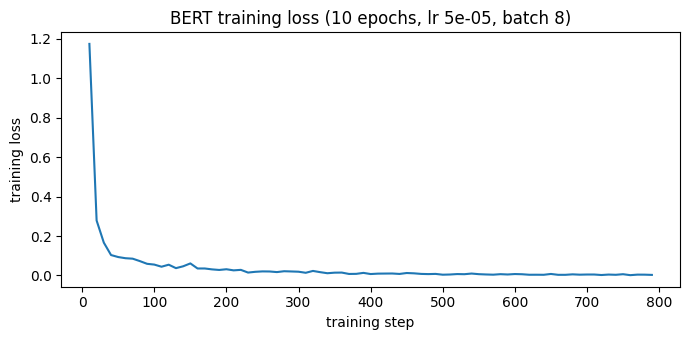

In [8]:
log = pd.DataFrame([h for h in trainer.state.log_history if "loss" in h])
log.to_csv(RESULTS / "bert_training_log.csv", index=False)

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(log["step"], log["loss"])
ax.set_xlabel("training step")
ax.set_ylabel("training loss")
ax.set_title(f"BERT training loss ({HP['epochs']} epochs, lr {HP['learning_rate']}, batch {HP['batch_size']})")
fig.tight_layout()
fig.savefig(RESULTS / "bert_training_loss.png", dpi=150)
plt.show()

## 4. Predict on the test set (word level)

Each word takes the prediction of its first sub-token. Words cut off by truncation get `O`. This gives one label per word, the same shape as the gold `ner_tags`.

In [9]:
def to_word_labels(n_words, word_ids, token_pred):
    labels = ["O"] * n_words          # words cut off by truncation stay "O"
    seen = set()
    for position, w in enumerate(word_ids):
        if w is None or w in seen:
            continue
        seen.add(w)
        labels[w] = ID2LABEL[int(token_pred[position])]
    return labels

test = ds["test"]
token_preds = trainer.predict(encoded["test"]).predictions.argmax(-1)
test_word_ids = [
    tokenizer(r["words"], is_split_into_words=True, truncation=True, max_length=MAX_LEN).word_ids() for r in test
]
word_preds = {
    r["key"]: to_word_labels(len(r["words"]), wid, pred)
    for r, wid, pred in zip(test, test_word_ids, token_preds)
}

with open(RESULTS / "bert_word_preds.json", "w", encoding="utf-8") as f:
    json.dump(word_preds, f)
print(f"Word-level predictions for {len(word_preds)} test receipts saved")

Word-level predictions for 347 test receipts saved


## 5. seqeval report (word level)

Entity-level precision / recall / F1. An entity counts as correct only if all of its words and its type are right.

In [10]:
from seqeval.metrics import classification_report

y_true = [[ID2LABEL[t] for t in r["ner_tags"]] for r in test]
y_pred = [word_preds[r["key"]] for r in test]
report = classification_report(y_true, y_pred, digits=4)
(RESULTS / "bert_seqeval.txt").write_text(report)
print(report)

              precision    recall  f1-score   support

     ADDRESS     0.8654    0.9078    0.8861       347
     COMPANY     0.8802    0.9107    0.8952       347
        DATE     0.9633    0.9827    0.9729       347
       TOTAL     0.7983    0.8329    0.8152       347

   micro avg     0.8763    0.9085    0.8921      1388
   macro avg     0.8768    0.9085    0.8923      1388
weighted avg     0.8768    0.9085    0.8923      1388



## 6. Field-level scores (`src/evaluate.py`, same as every method)

`bio_to_fields` joins each field's predicted words into a string, and `evaluate` compares the strings by exact match.
- **Main score:** against the gold rebuilt from the word tags.
- **Second score:** against the official ICDAR answers. Even a perfect tagger only reaches the ceiling shown, because of OCR noise.

In [11]:
from src.evaluate import bio_to_fields, evaluate, get_gold, get_official_gold, normalize, save_preds

bert_preds = {r["key"]: bio_to_fields(r["words"], word_preds[r["key"]]) for r in test}
save_preds(bert_preds, RESULTS / "bert_preds.json")

gold_test = get_gold(test)
official_gold = get_official_gold("test", keys=test["key"])   # streams the official answers (~1 min)

print("TEST, main gold (word tags)")
test_scores = evaluate(bert_preds, gold_test)
test_scores.to_csv(RESULTS / "bert_scores.csv")
print(test_scores.to_string())

print("\nTEST, official ICDAR answers")
official_scores = evaluate(bert_preds, official_gold)
official_scores.to_csv(RESULTS / "bert_scores_official.csv")
print(official_scores.to_string())

ceiling = evaluate(gold_test, official_gold)["f1"]

TEST, main gold (word tags)
           precision  recall     f1  correct  predicted  gold
field                                                        
company        89.57   89.05  89.31      309        345   347
date           97.98   97.69  97.84      339        346   347
address        91.07   91.07  91.07      316        347   347
total          90.29   88.47  89.37      307        340   347
macro_avg      92.23   91.57  91.90     <NA>       <NA>  <NA>

TEST, official ICDAR answers
           precision  recall     f1  correct  predicted  gold
field                                                        
company        73.04   72.62  72.83      252        345   347
date           95.09   94.81  94.95      329        346   347
address        55.62   55.62  55.62      193        347   347
total          87.35   85.59  86.46      297        340   347
macro_avg      77.78   77.16  77.47     <NA>       <NA>  <NA>


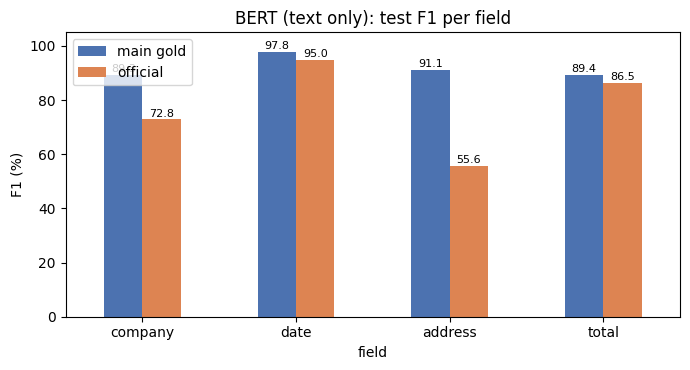

In [12]:
f1 = pd.DataFrame({"main gold": test_scores["f1"], "official": official_scores["f1"]}).drop("macro_avg")
ax = f1.plot.bar(rot=0, figsize=(7, 3.8), color=["#4C72B0", "#DD8452"])
ax.set_ylim(0, 105)
ax.set_ylabel("F1 (%)")
ax.set_title("BERT (text only): test F1 per field")
for p in ax.patches:
    ax.annotate(f"{p.get_height():.1f}", (p.get_x() + p.get_width() / 2, p.get_height() + 1), ha="center", fontsize=8)
plt.tight_layout()
plt.savefig(RESULTS / "bert_f1.png", dpi=150)
plt.show()

## 7. Where BERT fails (examples for the report)

In [13]:
for field in ["company", "address", "total", "date"]:
    wrong = [k for k, g in gold_test.items() if normalize(bert_preds[k][field], field) != normalize(g[field], field)]
    print(f"=== {field}: {len(wrong)} / {len(gold_test)} wrong ===")
    for k in wrong[:3]:
        print(f"  [{k}] PRED: {bert_preds[k][field]!r}\n                 GOLD: {gold_test[k][field]!r}")
    print()

=== company: 38 / 347 wrong ===
  [X51005230605] PRED: 'LANJAN SB ALSERKAM ENTERPRISE'
                 GOLD: 'PETRON BKT LANJAN SB'
  [X51005337877] PRED: 'JAPANESE CUISINE SDN BHD'
                 GOLD: 'UROKO JAPANESE CUISINE SDN BHD'
  [X51005442322] PRED: 'CITY GRAND COMPANIONS SON BHD'
                 GOLD: 'GRAND COMPANIONS SON BHD'

=== address: 31 / 347 wrong ===
  [X51005230621] PRED: 'LOT 13, JALAN LOT 13, JALAN IPOH, KG BATU 30 , ULU YAM LAMA 44300 BTG KALI, SELANGOR.'
                 GOLD: 'LOT 13, JALAN IPOH, KG BATU 30 , ULU YAM LAMA 44300 BTG KALI, SELANGOR.'
  [X51005361908] PRED: 'NO. 53, JALAN BESAR, 45600 BATANG BERJOMAT SELANGOR DARUL EHSAN'
                 GOLD: '(001451637-M)" NO. 53, JALAN BESAR, 45600 BATANG BERJOMAT SELANGOR DARUL EHSAN'
  [X51005447844] PRED: '13, JLN TASIK UTAMA 8 MEDAN NIAGA DAMAI SG BESI 57000 KL'
                 GOLD: '13, JLN TASIK UTAMA 8 MEDAN NIAGA DAMAI SG BESI'

=== total: 40 / 347 wrong ===
  [X51005200931] PRED: '411.50'
    

## 8. Summary, hyperparameters and download

In [14]:
summary = pd.DataFrame({
    "BERT F1, main gold": test_scores["f1"],
    "BERT F1, official": official_scores["f1"],
    "perfect-tagger ceiling (official)": ceiling,
}).round(1)
print(summary.to_string())

record = {
    **HP,
    "gpu": GPU,
    "train_minutes": round(TRAIN_MINUTES, 1),
    "train_receipts": len(ds["train"]),
    "test_receipts": len(test),
    "transformers": transformers.__version__,
    "torch": torch.__version__,
}
(RESULTS / "bert_hparams.json").write_text(json.dumps(record, indent=2))
record

           BERT F1, main gold  BERT F1, official  perfect-tagger ceiling (official)
field                                                                              
company                  89.3               72.8                               80.4
date                     97.8               95.0                               96.2
address                  91.1               55.6                               58.2
total                    89.4               86.5                               96.2
macro_avg                91.9               77.5                               82.8


{'model': 'bert-base-uncased',
 'max_length': 512,
 'learning_rate': 5e-05,
 'epochs': 10,
 'batch_size': 8,
 'weight_decay': 0.0,
 'warmup_steps': 0,
 'lr_scheduler': 'linear',
 'optimizer': 'AdamW (Trainer default)',
 'fp16': True,
 'seed': 42,
 'gpu': 'Tesla T4',
 'train_minutes': 2.3,
 'train_receipts': 626,
 'test_receipts': 347,
 'transformers': '5.22.1',
 'torch': '2.14.1+cu130'}

In Colab, the next cell downloads all `results/bert_*` files as one zip. Unzip it into the repo's `results/` folder. Then save this notebook with its outputs (File → Download → Download .ipynb) over `notebooks/03_bert_text_only.ipynb`.

In [15]:
import zipfile

bert_files = sorted(RESULTS.glob("bert_*"))
print("\n".join(p.name for p in bert_files))
try:
    from google.colab import files
except ImportError:
    files = None                      # running locally: the files are already in results/
if files is not None:
    with zipfile.ZipFile("bert_results.zip", "w") as z:
        for p in bert_files:
            z.write(p, p.name)
    files.download("bert_results.zip")

bert_f1.png
bert_hparams.json
bert_preds.json
bert_scores.csv
bert_scores_official.csv
bert_seqeval.txt
bert_training_log.csv
bert_training_loss.png
bert_word_preds.json


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>